In [1]:
import numpy as np
import seaborn as sns # optional
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show
import matplotlib.image as mpimg
import pathlib

In [2]:
sns.set_context('talk')

In [3]:
%matplotlib widget

Google Earth section

Now for the Sentinel 2 section

In [ ]:
file = 'sentinel-data/S2_2017-07-12/Sentinel-2_L2A_False_color.tiff'
s2_image = rasterio.open(file, 'r')

In [7]:
s2_image.indexes

(1, 2, 3)

In [8]:
s2_image.tags()

{'TIFFTAG_XRESOLUTION': '1',
 'TIFFTAG_YRESOLUTION': '1',
 'TIFFTAG_RESOLUTIONUNIT': '1 (unitless)',
 'AREA_OR_POINT': 'Area'}

In [9]:
with rasterio.open(file) as src:
    resolution = src.res
    bounds = src.bounds

In [23]:
print(resolution[0])
print(bounds)

8.988657844990755e-05
BoundingBox(left=-175.413508, bottom=-20.557035, right=-175.365958, top=-20.530619)


In [34]:
res_x = resolution[0]
res_y = resolution[1]
length_p = np.abs(bounds.left-bounds.right) / res_x
height_p = np.abs(bounds.top-bounds.bottom) / res_y
print(f'The image is {length_p} by {height_p } pixels')
length_m = length_p * 10
height_m = height_p * 10
image_area = length_m * height_m
print(f'The total area of the image is {image_area/1000000} km^2')

The image is 529.0 by 314.0 pixels
The total area of the image is 16.6106 km^2


In [30]:
length = np.abs(bounds.left-bounds.right)
length = np.abs(bounds.left-bounds.right)
image_area = length * height
print(f'The total area of the image is {length}')

The total area of the image is 0.04755000000000109


In [58]:
here = pathlib.Path('.')

In [59]:
files_2017 = list((here / 'sentinel-data/S2_2017-07-12').rglob('*.tiff'))
files_2018 = list((here / 'sentinel-data/S2_2018-07-12').rglob('*.tiff'))
files_2019 = list((here / 'sentinel-data/S2_2019-07-12').rglob('*.tiff'))

In [60]:
for i, file in enumerate(files_2019):
    print(f"{i}\t{file}")

0	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B01_Raw.tiff
1	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B02_Raw.tiff
2	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B03_Raw.tiff
3	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B04_Raw.tiff
4	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B05_Raw.tiff
5	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B06_Raw.tiff
6	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B07_Raw.tiff
7	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B08_Raw.tiff
8	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B09_Raw.tiff
9	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B11_Raw.tiff
10	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B12_Raw.tiff
11	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_B8A_Raw.tiff
12	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_False_color.tiff
13	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_False_color_urban.tiff
14	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_Highlight_Optimized_Natural_Color.tiff
15	sentinel-data\S2_2019-07-12\Sentinel-2_L2A_Moisture_index.tiff
16	sentinel-data\S2

In [63]:
b4 = rasterio.open(files_2019[3]).read(1)
b8 = rasterio.open(files_2019[7]).read(1)
veg_ind =(b8 - b4) / (b8 + b4)

C:\Users\march\AppData\Local\Temp\ipykernel_21728\1207137737.py:1: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b4 = rasterio.open(files_2019[3]).read(1)
C:\Users\march\AppData\Local\Temp\ipykernel_21728\1207137737.py:2: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b8 = rasterio.open(files_2019[7]).read(1)
C:\Users\march\AppData\Local\Temp\ipykernel_21728\1207137737.py:3: RuntimeWarning: invalid value encountered in divide
  veg_ind =(b8 - b4) / (b8 + b4)


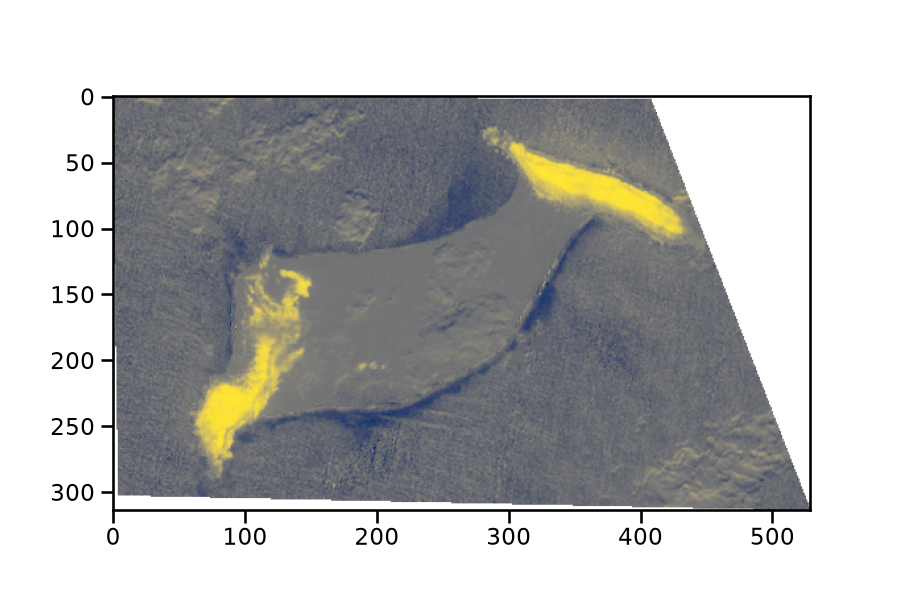

In [64]:
plt.close('all')
fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(veg_ind, cmap='cividis')
plt.show()